# **CMSE 202 Project Final Report**
## **What Makes a Song Popular on Spotify?**
#### Group members : Omar Abdulwahhab , Mohammed Alsayegh , Mint Menakanit, Prisha Kuma , Sai Palaka

## Introduction
Music streaming is a huge part of our life, and Spotify is one of the most popular platforms. Every day, millions of users listen to songs, creating data that reflects what people like. But a big question remains: what actually makes a song popular on Spotify? Is it the mood of the song, the energy, the artist's fame, or something else entirely?

In this project, we will investigate which musical features are most strongly associated with a song's popularity score on Spotify. Features like danceability, energy, loudness, tempo, and valence (the positivity of the song) might play a role. To explore these relationships, we worked with the Spotify Tracks Dataset (2006–2020) from Kaggle, which includes over 160,000 songs collected through Spotify’s Web API. Each song provides audio features such as danceability, energy, loudness, tempo, valence, speechiness, and a popularity score ranging from 0 to 100.

## Methods

To perform our analysis, we started by loading the Spotify dataset and displaying the first five rows to understand its structure. We cleaned the dataset to remove missing or invalid values. We conducted exploratory data analysis (EDA) to understand the distribution of features and to identify relationships with popularity, creating visualizations such as histograms, bar plots, and correlation heatmaps. Next, we used scikit-learn to train a simple Linear Regression model using key features like danceability, energy, tempo, and loudness to predict a song’s popularity score. We evaluated the model’s performance with Mean Squared Error (MSE) and interpreted the regression coefficients to identify which audio features have the strongest influence on popularity. We also enhanced the dataset with genre information retrieved via the Spotify Web API using Spotify.

#### __Data loading and cleaning process__
* #### By importing all Python packages essential to the project. We are able to use Pandas to work with the dataset, matplotlib and seaborn to create visualization, and scikit-learn to build a simple model. We then load data.csv (Spotify dataset) and display the first 5 rows to see what it looks like.

In [1]:
#Libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [2]:
data_spotify = pd.read_csv("data/data.csv")
data = data_spotify[data_spotify['year'] >= 2006]
data.head(5)

,valence,year,acousticness,artists,danceability,energy,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
16806,0.861,2006,0.262000,['Wham!'],0.757,0.618,0.000000,11,0.221,-7.964,0,Last Christmas - Remastered,83,11/11/06,0.0282,106.856
16807,0.136,2006,0.209000,['Snow Patrol'],0.563,0.592,0.000051,9,0.132,-4.571,1,Chasing Cars,79,1/1/06,0.0276,104.016
16808,0.843,2006,0.046000,"['Nelly Furtado', 'Timbaland']",0.795,0.978,0.000083,10,0.143,-6.097,0,Promiscuous,73,1/1/06,0.0459,114.321
16809,0.856,2006,0.050600,['My Chemical Romance'],0.463,0.857,0.000000,4,0.184,-3.063,1,Teenagers,78,10/23/06,0.0632,111.647
16810,0.236,2006,0.000289,['My Chemical Romance'],0.217,0.905,0.000110,2,0.222,-4.103,1,Welcome to the Black Parade,78,10/23/06,0.0752,96.950


* #### We are now checking what columns are in the dataset, what type of data each column holds, and if there are any missing values. The describe() function gives us basic stats like averages, minimums, and maximums.



In [3]:
print(data.info())
print(data.isnull().sum())
data.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 29619 entries, 16806 to 170652
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   valence           29619 non-null  float64
 1   year              29619 non-null  int64  
 2   acousticness      29619 non-null  float64
 3   artists           29619 non-null  object 
 4   danceability      29619 non-null  float64
 5   energy            29619 non-null  float64
 6   instrumentalness  29619 non-null  float64
 7   key               29619 non-null  int64  
 8   liveness          29619 non-null  float64
 9   loudness          29619 non-null  float64
 10  mode              29619 non-null  int64  
 11  name              29619 non-null  object 
 12  popularity        29619 non-null  int64  
 13  release_date      29619 non-null  object 
 14  speechiness       29619 non-null  float64
 15  tempo             29619 non-null  float64
dtypes: float64(9), int64(4), object(3)
memor

,valence,year,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,popularity,speechiness,tempo
count,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000
mean,0.475661,2013.024950,0.260327,0.596401,0.638718,0.078627,5.203687,0.190774,-7.325441,0.653871,56.376988,0.097655,121.702712
std,0.246183,4.325997,0.294086,0.172041,0.223329,0.230863,3.585099,0.156454,4.505309,0.475743,13.861501,0.105150,30.500128
min,0.000000,2006.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000
25%,0.282000,2009.000000,0.021200,0.489000,0.501000,0.000000,2.000000,0.096800,-8.419000,0.000000,50.000000,0.036100,97.477500
50%,0.464000,2013.000000,0.130000,0.608000,0.669000,0.000002,5.000000,0.125000,-6.264000,1.000000,57.000000,0.052100,121.064000
75%,0.666000,2017.000000,0.433000,0.723000,0.813000,0.000852,8.000000,0.239000,-4.757000,1.000000,65.000000,0.109000,141.947000
max,0.993000,2020.000000,0.996000,0.986000,1.000000,1.000000,11.000000,0.997000,1.342000,1.000000,100.000000,0.950000,220.099000


#### __Data analysis and visualization__
* #### A histogram was plotted to visualize how song popularity scores (0–100) are distributed.
  The x-axis (0 to 100) represents the popularity score, where 0 means a song is not popular at all and 100 means it is extremely popular on Spotify. The y-axis (0 to 35,000) represents the number of songs that fall within each popularity range. From the chart, we can see that most songs have average popularity score (close to 60), while only a smaller number of songs reach lower popularity scores (below 40).
   Most songs scored tend to be high, with only a small proportion below 40, showing that most of the songs doing well and popular enough.

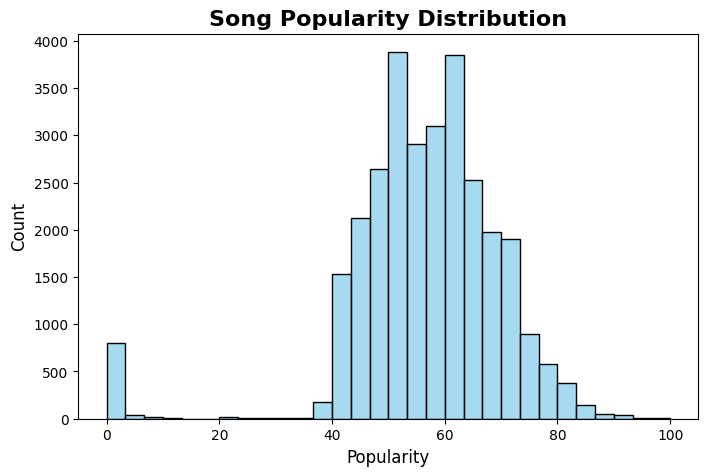

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(data['popularity'], bins=30, color='skyblue')
plt.title('Song Popularity Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Popularity', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

* #### We created a correlation heatmap of all the features to identify relationships with popularity.
    The values range from -1 to 1. A number closer to 1 means a strong positive relationship while a number closer to -1 means a strong negative relationship . A number near 0 means no clear relationship. From this heatmap, we see that year (0.86) has the strongest positive relationship with popularity, meaning newer songs tend to be more popular in this dataset. Features like energy (0.49) and loudness (0.46) also show a moderate positive relationship with popularity. On the other hand, acousticness (-0.57) is negatively correlated with popularity, which suggests that songs that are less acoustic (more electronic or energetic) tend to be more popular.

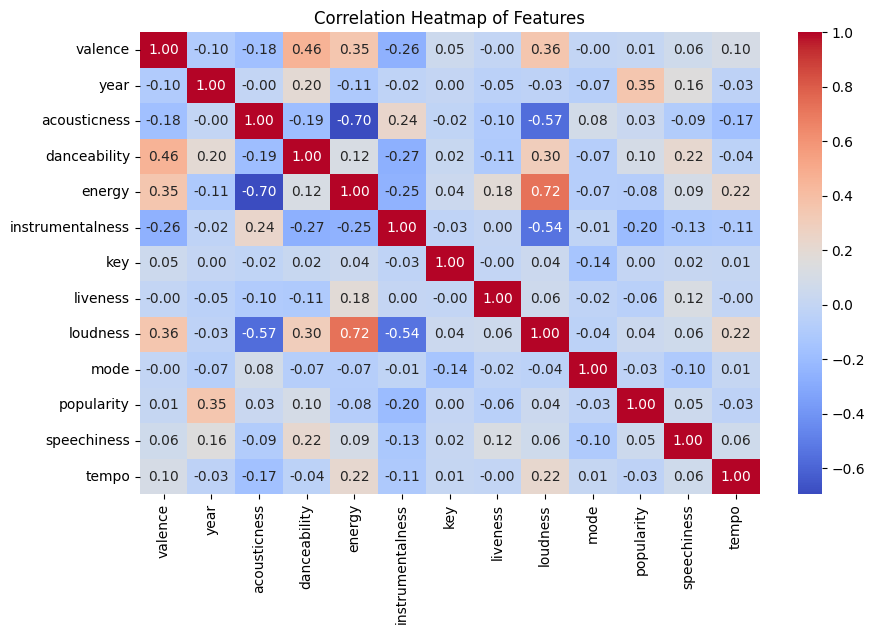

In [5]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


* #### We created scatter plot comparing each features to popularity to find more in depth relationships
  By excluding non-essential columns such as artists, name, and release_date, these plots show how each features effect popularity with most data clustered in certain parts. We can conclude the most effective feature that makes a song popular.



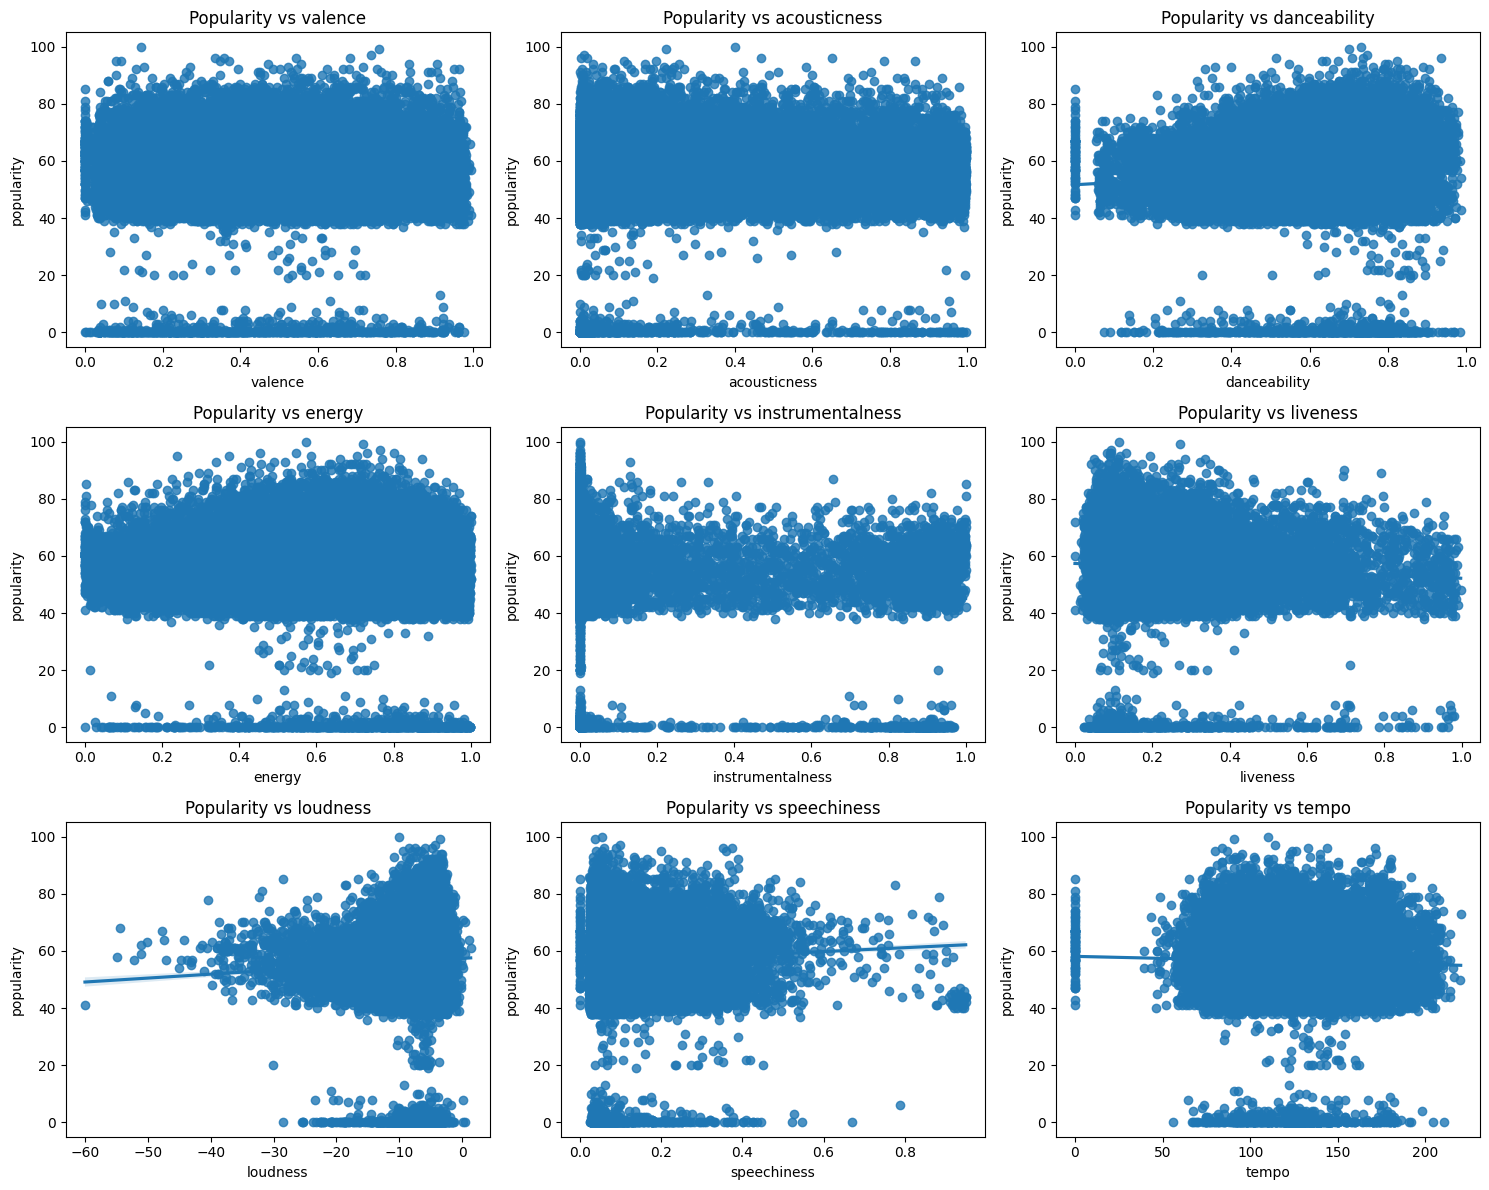

In [8]:
num_columns = len(data.columns)
exclude_columns = ['popularity', 'year', 'artists', 'name', 'release_date', 'mode', 'key']

features = []
for column in data.columns:
    if column not in exclude_columns:
        if data[column].dtype == 'int64':
            features.append(column)
        elif data[column].dtype == 'float64':
            features.append(column)

plt.figure(figsize=(15, 12))

for i in range(len(features)):
    plt.subplot(3, 3, i+1)
    sns.regplot(x=features[i], y='popularity', data=data)
    plt.title('Popularity vs ' + features[i])

plt.tight_layout()
plt.show()


#### __Model prediction__
* #### We built a Linear Regression model to predict song popularity based on selected audio features: danceability, energy, loudness, tempo, and valence.
  

In [ ]:
features = ['danceability', 'energy', 'loudness', 'tempo', 'valence']
X = data[features]
y = data['popularity']
X = X.dropna()
y = y.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")


This shows that while our model can recognize some patterns in the data, it cannot perfectly predict popularity because many other factors (like artist fame, marketing, or playlist placement) also play a big role in making a song popular.

In [ ]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})
print(coefficients)


Energy (33.15) and danceability (30.63) have the strongest positive effects, suggesting that upbeat and energetic songs are generally more popular. Loudness and tempo have very small positive effects, meaning they don’t impact popularity as much. Valence (-27.05), which measures how happy or positive a song is, surprisingly has a negative effect, possibly because slower or sad songs can still become hits.

# 🎵 Adding Genre Information Using Spotify Web API


### <span style="font-size:1.2em;">📦 Installing Spotipy library</span>
We are installing the Spotipy library, which allows us to connect to the Spotify Web API and fetch artist and genre information.


### <span style="font-size:1.2em;"> Authenticating with Spotify API</span>
In this cell, we use our `Client ID` and `Client Secret` to authenticate with the Spotify Web API.  
This will allow us to search for artists and get their genres.


In [ ]:
import spotipy
from spotipy.oauth2 import SpotifyClientCredentials

if 'sp' not in globals():
    # Your credentials
    client_id = "9fb6fc7ce5054c728c4434be3fbc00af"
    client_secret = "9a78cd17b150445c87e42d84e34699ed"

    sp = spotipy.Spotify(auth_manager=SpotifyClientCredentials(
        client_id=client_id,
        client_secret=client_secret
    ))
    print("Spotify API authenticated")
else:
    print("Spotify API already authenticated")


### <span style="font-size:1.2em;"> Adding genre information for each artist</span>
This cell defines a function that looks up an artist on Spotify and returns their genres.  
We then create a new `genres` column for each artist and simplify it to a single main genre.


In [ ]:
def get_genres_for_artist(artist_name):
    try:
        # Clean artist name
        if "[" in artist_name or "," in artist_name:
            artist_name = artist_name.split(",")[0].replace("[", "").replace("]", "").strip()

        # Search Spotify for the artist (flexible search)
        result = sp.search(q=artist_name, type="artist", limit=5)

        if result['artists']['items']:
            # Pick the artist with the highest popularity
            best_match = max(result['artists']['items'], key=lambda a: a['popularity'])
            return best_match['genres']
        return []
    except Exception as e:
        print(f"Error with artist {artist_name}: {e}")
        return []


# Add genres column
data['genres'] = data['artists'].apply(lambda x: get_genres_for_artist(x))

# Keep only the first genre as the main genre
data['main_genre'] = data['genres'].apply(lambda x: x[0] if x else "Unknown")

# Preview the new columns
data[['artists', 'main_genre']].head(10)


In [ ]:
get_genres_for_artist("Drake")


# Conclusion

From our analysis, we learned that a song’s popularity on Spotify is partly influenced by its audio features, but not completely determined by them. Features like energy and danceability show a strong positive relationship with popularity, meaning energetic and danceable songs are more likely to become hits. However, other features such as loudness and tempo have very little impact, and valence (happiness) even shows a negative effect, which suggests that sad or slower songs can still become popular. Our prediction model gave a Mean Squared Error of 323, meaning it can identify some trends but cannot fully predict popularity because factors like artist fame, marketing, and cultural trends play a big role. Overall, our project shows that while music features help explain popularity, there are many external influences that our dataset does not capture.



# Resources

Kaggle Dataset – https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks